
       NESTEROV (2012) RCDM PAGERANK BENCHMARK
n          | p    | gamma        | Groups   | Residual     | Time (s)  
---------------------------------------------------------------------------
65536      | 10   | 1/n          | 16       | 8.494e-04    | 1.80      
65536      | 10   | 1/sqrt(n)    | 16       | 8.020e-04    | 0.20      
65536      | 20   | 1/n          | 12       | 8.371e-04    | 0.24      
65536      | 20   | 1/sqrt(n)    | 12       | 7.719e-04    | 0.19      
262144     | 10   | 1/n          | 16       | 7.653e-04    | 1.36      
262144     | 10   | 1/sqrt(n)    | 16       | 7.269e-04    | 1.11      
262144     | 20   | 1/n          | 13       | 8.224e-04    | 1.19      
262144     | 20   | 1/sqrt(n)    | 13       | 8.132e-04    | 1.38      
1048576    | 10   | 1/n          | 16       | 7.753e-04    | 11.06     
1048576    | 10   | 1/sqrt(n)    | 15       | 9.964e-04    | 11.30     
1048576    | 20   | 1/n          | 12       | 9.687e-04    | 21.85     
1048576    |

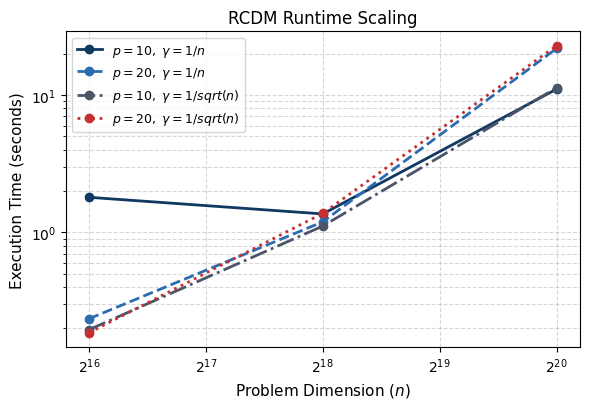

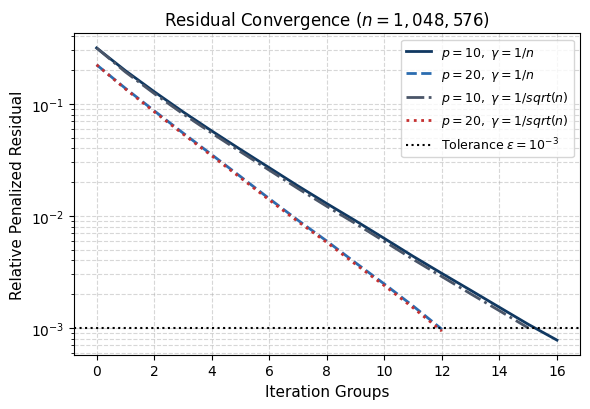

In [1]:

import time
import numpy as np
import numba
import matplotlib.pyplot as plt


# =============================================================================
# 1. GRAPH GENERATION
# =============================================================================

@numba.njit
def generate_graph(n, p, seed=42):
    """Generate a directed random graph with p distinct outgoing edges per node."""
    np.random.seed(seed)

    edges = np.empty((n, p), dtype=np.int32)
    diagonal_flags = np.zeros(n, dtype=np.bool_)

    for j in range(n):
        for r in range(p):
            while True:
                candidate = np.random.randint(0, n)

                # Reject duplicate edges.
                duplicate = False
                for s in range(r):
                    if edges[j, s] == candidate:
                        duplicate = True
                        break

                if not duplicate:
                    edges[j, r] = candidate
                    break

            if edges[j, r] == j:
                diagonal_flags[j] = True

    return edges, diagonal_flags


# =============================================================================
# 2. NESTEROV (2012) RCDM PAGERANK SOLVER
# =============================================================================

@numba.njit
def rcdm_google_solver(
    col_edges,
    L,
    cumsum_p,
    n,
    p,
    gamma,
    epsilon=1e-3,
    max_groups=500,
    seed=123,
):
    """
    Randomized Coordinate Descent Method for the penalized PageRank problem.

    One iteration group consists of n coordinate updates.
    """

    np.random.seed(seed)

    # Uniform initialization.
    x = np.full(n, 1.0 / n, dtype=np.float64)

    # Residual u = E_bar @ x - x.
    u = np.zeros(n, dtype=np.float64)

    for j in range(n):
        val = x[j] / p
        for r in range(p):
            u[col_edges[j, r]] += val

    u -= x

    # Penalty residual.
    v = np.sum(x) - 1.0

    # Store relative residual after each iteration group.
    history = np.empty(max_groups + 1, dtype=np.float64)

    residual = np.sqrt(np.dot(u, u) + gamma * v * v)
    history[0] = residual / np.linalg.norm(x)

    group_counter = 0

    while group_counter < max_groups:

        if history[group_counter] <= epsilon:
            break

        # Perform n coordinate updates.
        for _ in range(n):

            # Sample coordinate proportional to L_i.
            r_val = np.random.random()
            i = np.searchsorted(cumsum_p, r_val)

            if i >= n:
                i = n - 1

            # Partial derivative.
            dot_E_u = 0.0

            for r in range(p):
                dot_E_u += u[col_edges[i, r]]

            dot_E_u /= p

            grad_i = dot_E_u - u[i] + gamma * v

            # Coordinate update.
            h = -grad_i / L[i]
            x[i] += h

            # Update residual vector in O(p).
            h_over_p = h / p

            for r in range(p):
                u[col_edges[i, r]] += h_over_p

            u[i] -= h
            v += h

        group_counter += 1

        # Relative residual of the penalized objective.
        residual = np.sqrt(np.dot(u, u) + gamma * v * v)
        history[group_counter] = residual / np.linalg.norm(x)

    return group_counter, history[:group_counter + 1]


# =============================================================================
# 3. EXPERIMENTAL BENCHMARK
# =============================================================================

def run_benchmark():

    n_list = [65536, 262144, 1048576]
    p_list = [10, 20]

    gamma_configs = [
        ("1/n", lambda n: 1.0 / n),
        ("1/sqrt(n)", lambda n: 1.0 / np.sqrt(n)),
    ]

    epsilon = 1e-3
    max_groups = 500

    results = []
    histories = {}

    print("\n" + "=" * 75)
    print("       NESTEROV (2012) RCDM PAGERANK BENCHMARK")
    print("=" * 75)

    print(
        f"{'n':<10} | {'p':<4} | {'gamma':<12} | "
        f"{'Groups':<8} | {'Residual':<12} | {'Time (s)':<10}"
    )
    print("-" * 75)

    for n in n_list:

        for p in p_list:

            # Generate graph once for each (n, p).
            col_edges, diagonal_flags = generate_graph(n, p)

            for gamma_label, gamma_function in gamma_configs:

                gamma = gamma_function(n)

                # Coordinate-wise Lipschitz constants.
                L = np.where(
                    diagonal_flags,
                    1.0 - 1.0 / p + gamma,
                    1.0 + 1.0 / p + gamma,
                )

                # Sampling probabilities proportional to L_i.
                probabilities = L / np.sum(L)
                cumsum_p = np.cumsum(probabilities)
                cumsum_p[-1] = 1.0

                # Run solver.
                start = time.perf_counter()

                groups, history = rcdm_google_solver(
                    col_edges,
                    L,
                    cumsum_p,
                    n,
                    p,
                    gamma,
                    epsilon,
                    max_groups,
                )

                elapsed = time.perf_counter() - start

                final_residual = history[-1]

                print(
                    f"{n:<10} | {p:<4} | {gamma_label:<12} | "
                    f"{groups:<8} | {final_residual:<12.3e} | "
                    f"{elapsed:<10.2f}"
                )

                results.append({
                    "n": n,
                    "p": p,
                    "gamma": gamma_label,
                    "groups": groups,
                    "residual": final_residual,
                    "time": elapsed,
                })

                histories[(n, p, gamma_label)] = history

            del col_edges, diagonal_flags, L, probabilities, cumsum_p

    print("=" * 75)

    return results, histories


# =============================================================================
# 4. PLOTTING
# =============================================================================

def generate_plots(results, histories):

    navy = "#103861"
    blue = "#2B6CB0"
    slate = "#4A5568"
    red = "#C53030"

    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.size": 10,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
    })

    # -------------------------------------------------------------------------
    # Figure 1: Runtime scaling
    # -------------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(6, 4.2))

    styles = [
        (10, "1/n", navy, "-"),
        (20, "1/n", blue, "--"),
        (10, "1/sqrt(n)", slate, "-."),
        (20, "1/sqrt(n)", red, ":"),
    ]

    for p, gamma, color, linestyle in styles:

        subset = [
            r for r in results
            if r["p"] == p and r["gamma"] == gamma
        ]

        subset.sort(key=lambda r: r["n"])

        ax.plot(
            [r["n"] for r in subset],
            [r["time"] for r in subset],
            marker="o",
            color=color,
            linestyle=linestyle,
            linewidth=2,
            label=fr"$p={p},\ \gamma={gamma}$",
        )

    ax.set_xscale("log", base=2)
    ax.set_yscale("log")
    ax.set_xlabel("Problem Dimension ($n$)")
    ax.set_ylabel("Execution Time (seconds)")
    ax.set_title("RCDM Runtime Scaling")
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.legend()

    plt.tight_layout()
    plt.savefig("rcdm_scalability.png")
    plt.show()

    # -------------------------------------------------------------------------
    # Figure 2: Actual residual convergence
    # -------------------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(6, 4.2))

    n = max(r["n"] for r in results)

    configurations = [
        (10, "1/n", navy, "-"),
        (20, "1/n", blue, "--"),
        (10, "1/sqrt(n)", slate, "-."),
        (20, "1/sqrt(n)", red, ":"),
    ]

    for p, gamma, color, linestyle in configurations:

        history = histories[(n, p, gamma)]

        ax.plot(
            np.arange(len(history)),
            history,
            color=color,
            linestyle=linestyle,
            linewidth=2,
            label=fr"$p={p},\ \gamma={gamma}$",
        )

    ax.axhline(
        y=1e-3,
        color="black",
        linestyle=":",
        label=r"Tolerance $\epsilon=10^{-3}$",
    )

    ax.set_yscale("log")
    ax.set_xlabel("Iteration Groups")
    ax.set_ylabel("Relative Penalized Residual")
    ax.set_title(fr"Residual Convergence ($n={n:,}$)")
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.legend()

    plt.tight_layout()
    plt.savefig("rcdm_convergence.png")
    plt.show()


# =============================================================================
# 5. MAIN
# =============================================================================

if __name__ == "__main__":

    benchmark_results, convergence_histories = run_benchmark()

    generate_plots(
        benchmark_results,
        convergence_histories,
    )
